# Laboratorio de Inteligencia Artificial: Clasificación Binaria con PyTorch

En este laboratorio implementaremos un modelo de clasificación binaria utilizando redes neuronales en **PyTorch**. 
El dataset elegido es el **Default of Credit Card Clients**, el cual cuenta con 30,000 registros y 23 características financieras. El objetivo es predecir si un cliente caerá en mora el próximo mes (0 = No, 1 = Sí).

Al existir un desbalance en las clases (hay menos personas en mora que personas al día), aplicaremos **Sobremuestreo (Oversampling)** en el conjunto de entrenamiento para no eliminar datos, respetando las buenas prácticas.

In [1]:
%pip install ucimlrepo imbalanced-learn scikit-learn pandas torch matplotlib


   -------------------------- ------------- 2/3 [imbalanced-learn]
   -------------------------- ------------- 2/3 [imbalanced-learn]
   -------------------------- ------------- 2/3 [imbalanced-learn]
   -------------------------- ------------- 2/3 [imbalanced-learn]
   ---------------------------------------- 3/3 [imbalanced-learn]

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Instalación de librerías necesarias (ejecutar solo la primera vez)
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

## 1. Carga del Dataset
Utilizamos la librería oficial de UCI para descargar el dataset directamente. Extraemos las características ($X$) y la variable objetivo ($y$).

In [3]:
# Descargar el dataset "Default of Credit Card Clients" (ID: 350)
print("Descargando dataset...")
credit_card_data = fetch_ucirepo(id=350)

# Extraer X (características) e y (objetivo)
X = credit_card_data.data.features
y = credit_card_data.data.targets

# Visualizar las dimensiones
print(f"Dimensiones de X (Características): {X.shape}")
print(f"Dimensiones de y (Objetivo): {y.shape}")
print("\nDistribución original de la variable objetivo:")
print(y.value_counts())

Descargando dataset...
Dimensiones de X (Características): (30000, 23)
Dimensiones de y (Objetivo): (30000, 1)

Distribución original de la variable objetivo:
Y
0    23364
1     6636
Name: count, dtype: int64


## 2. Preprocesamiento: Partición y Escalado
Primero separamos los datos en conjuntos de Entrenamiento y Prueba (80% - 20%). 
Luego, aplicamos escalado (`StandardScaler`) para estandarizar los datos y ayudar a que el método del gradiente converja más rápido.

In [4]:
# Separar datos en entrenamiento (train) y prueba (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Estandarizar los datos numéricos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensiones X_train_scaled: {X_train_scaled.shape}")
print(f"Dimensiones X_test_scaled: {X_test_scaled.shape}")

Dimensiones X_train_scaled: (24000, 23)
Dimensiones X_test_scaled: (6000, 23)


## 3. Balanceo de Datos (Sobremuestreo)
Para evitar el sobreajuste hacia la clase mayoritaria (clientes que no caen en mora), rellenamos datos de la clase minoritaria utilizando `RandomOverSampler`. **Esto duplica registros existentes aleatoriamente sin eliminar ningún dato.**

In [5]:
# Aplicar Oversampling SOLO al conjunto de entrenamiento
ros = RandomOverSampler(random_state=42)
X_train_bal, y_train_bal = ros.fit_resample(X_train_scaled, y_train)

print("Distribución de 'y' en entrenamiento DESPUÉS del balanceo:")
print(y_train_bal.value_counts())

Distribución de 'y' en entrenamiento DESPUÉS del balanceo:
Y
0    18691
1    18691
Name: count, dtype: int64


## 4. Conversión a Tensores de PyTorch
Las redes neuronales de PyTorch requieren que los datos estén en formato de Tensores (matrices optimizadas para el cálculo del gradiente).

In [6]:
# Convertir los arrays de NumPy a tensores de PyTorch
# Se usa torch.float32 para operaciones numéricas en PyTorch
X_train_tensor = torch.tensor(X_train_bal, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_bal.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

print("Datos convertidos a tensores de PyTorch exitosamente.")

Datos convertidos a tensores de PyTorch exitosamente.


## 5. Definición de la Red Neuronal, Función de Coste y Optimizador
Creamos una Red Neuronal de dos capas (que puede actuar conceptualmente como una regresión logística avanzada).
* **Coste:** Usaremos `BCEWithLogitsLoss` (Binary Cross Entropy), ideal para clasificación binaria, ya que combina la función Sigmoide y la pérdida en una sola capa matemática de forma más estable.
* **Optimizador:** Usaremos SGD (Gradiente Descendente Estocástico) para actualizar los pesos de la red.

In [7]:
# Definir la arquitectura de la red neuronal
class RedClasificacionBinaria(nn.Module):
    def __init__(self, input_dim):
        super(RedClasificacionBinaria, self).__init__()
        # Capa oculta
        self.capa1 = nn.Linear(input_dim, 16)
        self.relu = nn.ReLU()
        # Capa de salida (1 neurona para binario)
        self.salida = nn.Linear(16, 1)
        
    def forward(self, x):
        x = self.capa1(x)
        x = self.relu(x)
        out = self.salida(x)
        return out

# Inicializar modelo
input_dimension = X_train_tensor.shape[1]
modelo = RedClasificacionBinaria(input_dimension)

# Definir la función de coste y el optimizador (Gradiente Descendente)
criterio = nn.BCEWithLogitsLoss()
optimizador = optim.SGD(modelo.parameters(), lr=0.01)

print(modelo)

RedClasificacionBinaria(
  (capa1): Linear(in_features=23, out_features=16, bias=True)
  (relu): ReLU()
  (salida): Linear(in_features=16, out_features=1, bias=True)
)


## 6. Entrenamiento del Modelo (Método del Gradiente)
Ejecutaremos un bucle de entrenamiento (Epochs). En cada iteración:
1. Calculamos la predicción (Forward pass).
2. Medimos el error usando la función de Coste.
3. Propagamos el error hacia atrás (Backward pass).
4. Actualizamos los pesos (Step del Optimizador).

Época [300/1500], Coste: 0.6597
Época [600/1500], Coste: 0.6325
Época [900/1500], Coste: 0.6183
Época [1200/1500], Coste: 0.6099
Época [1500/1500], Coste: 0.6040


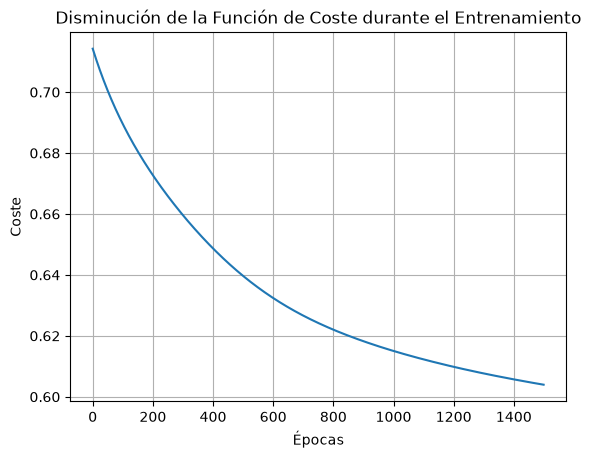

In [8]:
# Bucle de entrenamiento
epocas = 1500
historial_coste = []

for epoca in range(epocas):
    # 1. Forward Pass: calcular la predicción
    predicciones = modelo(X_train_tensor)
    
    # 2. Calcular la pérdida (Coste)
    coste = criterio(predicciones, y_train_tensor)
    
    # 3. Limpiar gradientes previos, calcular nuevos (Backward pass) y actualizar pesos
    optimizador.zero_grad()
    coste.backward()
    optimizador.step()
    
    # Guardar coste para graficar
    historial_coste.append(coste.item())
    
    # Imprimir progreso cada 300 épocas
    if (epoca+1) % 300 == 0:
        print(f'Época [{epoca+1}/{epocas}], Coste: {coste.item():.4f}')

# Graficar la curva de aprendizaje
plt.plot(historial_coste)
plt.title('Disminución de la Función de Coste durante el Entrenamiento')
plt.xlabel('Épocas')
plt.ylabel('Coste')
plt.grid(True)
plt.show()

## 7. Evaluación del Modelo (Métricas)
Utilizando lo aprendido en el cuaderno de métricas de clasificación, pasaremos el modelo al modo de evaluación y predeciremos sobre el conjunto de prueba (Test). Al ser la salida "logits", aplicamos la función sigmoide y un umbral de $0.5$ para decidir las clases (0 o 1).

In [9]:
# Cambiar el modelo a modo evaluación
modelo.eval()

# Desactivar el cálculo de gradientes para evaluación
with torch.no_grad():
    # Obtener predicciones "crudas" (logits)
    y_test_pred_logits = modelo(X_test_tensor)
    
    # Aplicar sigmoide para convertirlas a probabilidades
    y_test_pred_prob = torch.sigmoid(y_test_pred_logits)
    
    # Umbral de decisión en 0.5 (True o False, luego pasados a 1 y 0)
    y_test_pred_clase = (y_test_pred_prob >= 0.5).float()

# Convertir nuevamente a Numpy para usar Scikit-Learn
y_real = y_test_tensor.numpy()
y_pred = y_test_pred_clase.numpy()

# Cálculo de métricas
acc = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred)
recall = recall_score(y_real, y_pred)
f1 = f1_score(y_real, y_pred)
matriz_conf = confusion_matrix(y_real, y_pred)

print("=== MÉTRICAS DE CLASIFICACIÓN ===")
print(f"Accuracy (Exactitud): {acc:.4f}")
print(f"Precision (Precisión): {precision:.4f}")
print(f"Recall (Sensibilidad): {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print("\nMatriz de Confusión:")
print(matriz_conf)

=== MÉTRICAS DE CLASIFICACIÓN ===
Accuracy (Exactitud): 0.7350
Precision (Precisión): 0.4237
Recall (Sensibilidad): 0.5501
F1-Score: 0.4787

Matriz de Confusión:
[[3680  993]
 [ 597  730]]
